# Step:1 load data into jupyter notebook

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# inline says display matplotlib picture inline( not as popup)
%matplotlib inline

In [2]:
df= pd.read_excel('pima-data.xlsx')

In [3]:
df.head()

,num_preg,glucose_conc,diastolic_bp,thickness,insulin,bmi,diab_pred,age,diabetes_orig,skin,has_diabetes,diabetes
0,6,148,72,35,0,33.6,0.627,50,1,1.3790,True,True
1,1,85,66,29,0,26.6,0.351,31,0,1.1426,False,False
2,8,183,64,0,0,23.3,0.672,32,1,0.0000,True,True
3,1,89,66,23,94,28.1,0.167,21,0,0.9062,False,False
4,0,137,40,35,168,43.1,2.288,33,1,1.3790,True,True


# checks for the null values 

In [4]:
# check if any columns has unused values, no values, or duplicate values.......these columns has to be eliminated
# else some algorithms might get the confused with above and start under-reperforming

In [5]:
df.isnull().sum()

num_preg         0
glucose_conc     0
diastolic_bp     0
thickness        0
insulin          0
bmi              0
diab_pred        0
age              0
diabetes_orig    0
skin             0
has_diabetes     0
diabetes         0
dtype: int64

In [6]:
len(df)

768

In [7]:
df.shape

(768, 12)

In [8]:
df.describe()

,num_preg,glucose_conc,diastolic_bp,thickness,insulin,bmi,diab_pred,age,diabetes_orig,skin
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958,0.809136
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951,0.628517
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000,0.906200
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000,1.260800
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000,3.900600


# Step 2: clean the data

### 2a-let us find if there are any null values

In [9]:
df.isnull().values.any()

False

### 2.b  let us find duplicate columns or co-related columns

In [10]:
# first check how many columns are there--------> 12

In [11]:
def plot_corr(df, size=12):
    corr = df.corr()# pandas dataframe correlation function
    fig, ax= plt.subplots(figsize=(size,size))
    ax.matshow(corr) # color code the rectangles by correlation values
    plt.xticks(range(len(corr.columns)), corr.columns)
    plt.yticks(range(len(corr.columns)), corr.columns)

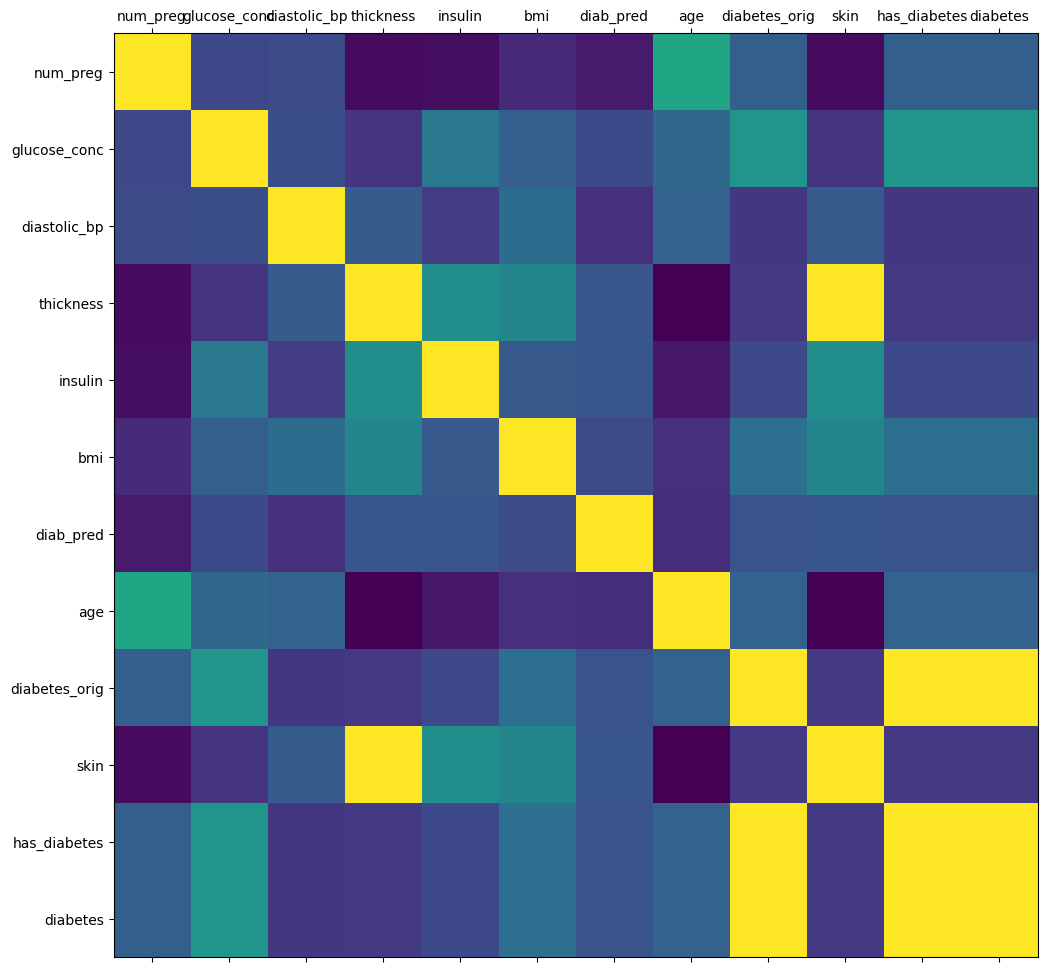

In [12]:
# let's call above function 
plot_corr(df)

In [13]:
# we are going to remove thickness, diabetes_orig ,has_diabetes

In [14]:
del df['thickness']
del df['has_diabetes']
del df['diabetes_orig']

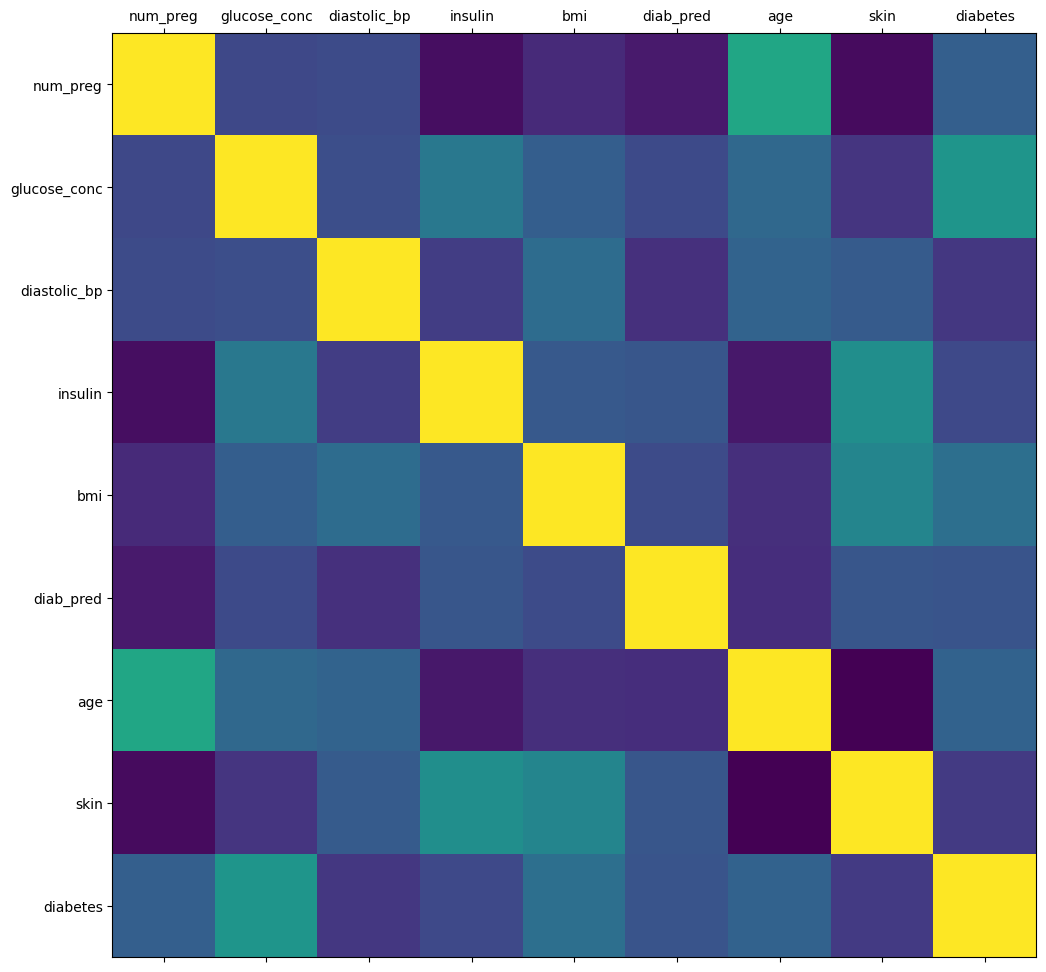

In [15]:
plot_corr(df)

In [16]:
df.head()

,num_preg,glucose_conc,diastolic_bp,insulin,bmi,diab_pred,age,skin,diabetes
0,6,148,72,0,33.6,0.627,50,1.3790,True
1,1,85,66,0,26.6,0.351,31,1.1426,False
2,8,183,64,0,23.3,0.672,32,0.0000,True
3,1,89,66,94,28.1,0.167,21,0.9062,False
4,0,137,40,168,43.1,2.288,33,1.3790,True


### 2.c-  let's convert text to numberss
##### ML algorithms will not understand text , so convert to numbers

In [17]:
diabetes_map={True:1, False:0}
df['diabetes']= df['diabetes'].map(diabetes_map)

In [18]:
df.head()

,num_preg,glucose_conc,diastolic_bp,insulin,bmi,diab_pred,age,skin,diabetes
0,6,148,72,0,33.6,0.627,50,1.3790,1
1,1,85,66,0,26.6,0.351,31,1.1426,0
2,8,183,64,0,23.3,0.672,32,0.0000,1
3,1,89,66,94,28.1,0.167,21,0.9062,0
4,0,137,40,168,43.1,2.288,33,1.3790,1


In [19]:
df.shape

(768, 9)

In [20]:
df.head()

,num_preg,glucose_conc,diastolic_bp,insulin,bmi,diab_pred,age,skin,diabetes
0,6,148,72,0,33.6,0.627,50,1.3790,1
1,1,85,66,0,26.6,0.351,31,1.1426,0
2,8,183,64,0,23.3,0.672,32,0.0000,1
3,1,89,66,94,28.1,0.167,21,0.9062,0
4,0,137,40,168,43.1,2.288,33,1.3790,1


In [21]:
# we will use naive baise and logistic regression algorithms  to trained the model

### let's check the proportion of diabetes vs non-diabetes data

#### we need to ensure that the proportion should be balanced (50 - 50) diabetes and non 
#### diabetes or at least close enough to proceed

In [22]:
num_true = len(df.loc[df['diabetes']==True])
num_false = len(df.loc[df['diabetes']==False])
print("true=", (num_true / (num_true + num_false))*100)
print("false=", (num_false / (num_true + num_false))*100)

true= 34.89583333333333
false= 65.10416666666666


#### in case of data imbalance we use SMOTE techinque to uncrease lesser data sample .

# Step 3. Train-test-split

#### let's split our data for training and testing  the algorithms

In [29]:
from sklearn.model_selection import train_test_split
feature_col_names = ['num_preg','glucose_conc','diastolic_bp','insulin','bmi','diab_pred','age']
predicted_class_names = ['diabetes']
x = df[feature_col_names].values
y= df[predicted_class_names].values
split_test_size = 0.30
x_train, x_test, y_train, y_test= train_test_split(x,y,
                                                   test_size= split_test_size, random_state=42)

In [24]:
df.head()

,num_preg,glucose_conc,diastolic_bp,insulin,bmi,diab_pred,age,skin,diabetes
0,6,148,72,0,33.6,0.627,50,1.3790,1
1,1,85,66,0,26.6,0.351,31,1.1426,0
2,8,183,64,0,23.3,0.672,32,0.0000,1
3,1,89,66,94,28.1,0.167,21,0.9062,0
4,0,137,40,168,43.1,2.288,33,1.3790,1


In [27]:
df.shape

(768, 9)

In [30]:
# make sure training data and testing data is 70% and 30%

print('{0:0.2f}% in training set'.format((len(x_train)/len(df.index))*100))
print('{0:0.2f}% in testing set'.format((len(x_test)/len(df.index))*100))

69.92% in training set
30.08% in testing set


In [31]:
### verifying the 

In [34]:
# original data has 35% diabetes true  and  65% diabetes false.. same should persist after split
# print('{training true: {0} ({1:0.2}%)}'.format(len(y_train[y_train[:]==1]),(len(y_train[y_train[:]==1])/len(y_train)*100)))
# print('{training false: {0} ({1:0.2}%)}'.format(len(y_train[y_train[:]==0]),(len(y_train[y_train[:]==0])/len(y_train)*100)))

# print('{test true: {0} ({1:0.2}%)}'.format(len(y_test[y_test[:]==1]),(len(y_test[y_test[:]==1])/len(y_test)*100)))
# print('{test false: {0} ({1:0.2}%)}'.format(len(y_test[y_test[:]==0]),(len(y_test[y_test[:]==0])/len(y_test)*100)))
# # hence it is predicting



print('training true: {0} ({1:0.2%})'.format(len(y_train[y_train[:] == 1]), len(y_train[y_train[:] == 1]) / len(y_train)))
print('training false: {0} ({1:0.2%})'.format(len(y_train[y_train[:] == 0]), len(y_train[y_train[:] == 0]) / len(y_train)))

print('test true: {0} ({1:0.2%})'.format(len(y_test[y_test[:] == 1]), len(y_test[y_test[:] == 1]) / len(y_test)))
print('test false: {0} ({1:0.2%})'.format(len(y_test[y_test[:] == 0]), len(y_test[y_test[:] == 0]) / len(y_test)))

training true: 188 (35.01%)
training false: 349 (64.99%)
test true: 80 (34.63%)
test false: 151 (65.37%)


In [36]:
print('# rows in dataframe {0}'.format(len(df)))
print('# rows in missing glucose_conc : {0}'.format(len(df.loc[df['glucose_conc']
                                                               ==0
                                                              ])))
print('# rows missing diastolic_bp : {0}'.format(len(df.loc[df['diastolic_bp']
                                                           ==0
                                                           ])))
print('# rows missing thickness : {0}'.format(len(df.loc[df['skin']
                                                           ==0
                                                           ])))

print('# rows missing insulin : {0}'.format(len(df.loc[df['insulin']
                                                           ==0
                                                           ])))
print('# rows missing bmi : {0}'.format(len(df.loc[df['bmi']
                                                           ==0
                                                           ])))
print('# rows missing diab_pred : {0}'.format(len(df.loc[df['diab_pred']
                                                           ==0
                                                           ])))

print('# rows missing age : {0}'.format(len(df.loc[df['age']
                                                           ==0
                                                           ])))

# rows in dataframe 768
# rows in missing glucose_conc : 5
# rows missing diastolic_bp : 35
# rows missing thickness : 227
# rows missing insulin : 374
# rows missing bmi : 11
# rows missing diab_pred : 0
# rows missing age : 0


In [41]:
#  let's fill 0's with valid data  (either mean or mode)

In [43]:
from sklearn.impute import SimpleImputer  #the purpose of simpleimputer is whenever 0 is there replace with mean 

In [50]:
# Initialize SimpleImputer (replaces Imputer)
fill_0 = SimpleImputer(missing_values=0, strategy="mean")

# Fit and transform your dataset
x_train = fill_0.fit_transform(x_train)
x_test = fill_0.fit_transform(x_test)

In [51]:
x_train[0:10]

array([[1.00000000e+00, 9.50000000e+01, 6.00000000e+01, 5.80000000e+01,
        2.39000000e+01, 2.60000000e-01, 2.20000000e+01],
       [5.00000000e+00, 1.05000000e+02, 7.20000000e+01, 3.25000000e+02,
        3.69000000e+01, 1.59000000e-01, 2.80000000e+01],
       [4.34056399e+00, 1.35000000e+02, 6.80000000e+01, 2.50000000e+02,
        4.23000000e+01, 3.65000000e-01, 2.40000000e+01],
       [4.00000000e+00, 1.31000000e+02, 6.80000000e+01, 1.66000000e+02,
        3.31000000e+01, 1.60000000e-01, 2.80000000e+01],
       [1.00000000e+00, 1.03000000e+02, 3.00000000e+01, 8.30000000e+01,
        4.33000000e+01, 1.83000000e-01, 3.30000000e+01],
       [2.00000000e+00, 8.20000000e+01, 5.20000000e+01, 1.15000000e+02,
        2.85000000e+01, 1.69900000e+00, 2.50000000e+01],
       [3.00000000e+00, 1.28000000e+02, 7.80000000e+01, 1.55333333e+02,
        2.11000000e+01, 2.68000000e-01, 5.50000000e+01],
       [1.00000000e+00, 1.22000000e+02, 6.40000000e+01, 1.56000000e+02,
        3.51000000e+01, 6

# Step 4: train the model

In [55]:
from sklearn.naive_bayes import GaussianNB
# create gaussian naive bayes model object and train it with data
nb_model= GaussianNB()
nb_model.fit(x_train,y_train.ravel())

GaussianNB()

In [56]:
# let's test the algorithm's accuracy with training data itself
nb_predict_train = nb_model.predict(x_train)
from sklearn import metrics
print('accuracy: {0:4f}'.format(metrics.accuracy_score(y_train,
                                                      nb_predict_train)))

accuracy: 0.759777


# Step 5: Testing the model

In [57]:
nb_predict_test = nb_model.predict(x_test)
from sklearn import metrics
print('accuracy: {0:4f}'.format(metrics.accuracy_score(y_test,
                                                      nb_predict_test)))

accuracy: 0.748918


# Algorithms Performance

In [58]:
print('confusion matrix')
print('{0}'.format(metrics.confusion_matrix(y_test,nb_predict_test)))
print('')
print('classification report')
print(metrics.classification_report(y_test, nb_predict_test))

confusion matrix
[[121  30]
 [ 28  52]]

classification report
              precision    recall  f1-score   support

           0       0.81      0.80      0.81       151
           1       0.63      0.65      0.64        80

    accuracy                           0.75       231
   macro avg       0.72      0.73      0.72       231
weighted avg       0.75      0.75      0.75       231



### final observation of naive bayes algo ==> accuracy 73%, recall 81%
### type 2 error values should be less compared to type 1 error

In [59]:
# let's try random forest algorithms

In [62]:
# from sklearn.ensemble import RandomForestClassifier
# rf_model = RandomForestClassifier(random_state=42)
# rf_model.fit(x_train,y_train.model.ravel())
# rf_predict_test= rf_model.predict(x_test)
# # trining metrix
# print('accuracy : {0:,4f}'.format(metrics.accuracy_score(y_test,rf_predict_test)))


from sklearn import metrics
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(random_state=42)

# Fix: call .ravel() directly on y_train
rf_model.fit(x_train, y_train.ravel())

rf_predict_test = rf_model.predict(x_test)

# Print accuracy
print("accuracy : {0:.4f}".format(metrics.accuracy_score(y_test, rf_predict_test)))

accuracy : 0.7619


In [63]:
# let's see confusion metrix and classification report

In [64]:
print(metrics.confusion_matrix(y_test, rf_predict_test))
print('')
print('classification report')
print(metrics.classification_report(y_test, rf_predict_test))

[[122  29]
 [ 26  54]]

classification report
              precision    recall  f1-score   support

           0       0.82      0.81      0.82       151
           1       0.65      0.68      0.66        80

    accuracy                           0.76       231
   macro avg       0.74      0.74      0.74       231
weighted avg       0.76      0.76      0.76       231



In [65]:
# let's try with logistic regression algorithms

In [77]:
from sklearn.linear_model import LogisticRegression
lr_model= LogisticRegression(class_weight='balanced' ,C= 0.2, random_state=42)# c is hypermeter
lr_model.fit(x_train, y_train.ravel())
lr_predict_test = lr_model.predict(x_test)

# trainig metrics
print('accuracy: {0:.4f}'.format(metrics.accuracy_score(y_test, lr_predict_test)))
print('')
print(metrics.confusion_matrix(y_test, lr_predict_test))
print('')
print('classification report')
print(metrics.classification_report(y_test, lr_predict_test))
# Notes: Random forest algorithms is best for classification at c=0.2

accuracy: 0.6926

[[108  43]
 [ 28  52]]

classification report
              precision    recall  f1-score   support

           0       0.79      0.72      0.75       151
           1       0.55      0.65      0.59        80

    accuracy                           0.69       231
   macro avg       0.67      0.68      0.67       231
weighted avg       0.71      0.69      0.70       231



C:\Users\AKASH KUMAR\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:460: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


# final conclusion ---> we are suggesting random forest algorithms for this project as the accuracy is 75%
# and recall value is 82% which is higher than other 2 algorithms (i.e  naive bayes and logistic regression algorithms)